# Quickstart: LIANA+'s consensus with Null B

`ccc_nulls.rank_aggregate` runs LIANA+'s `rank_aggregate` with CellChat as a sixth method, and replaces the
p-value of the two permutation tools (CellPhoneDB, CellChat) with **Null B**: an interaction is specific only if
the ligand side is specific to the sender **and** the receptor side to the receiver. Everything else is LIANA+'s.

This notebook uses the 700-cell PBMC data bundled with scanpy, so it needs no download.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import liana as li
import scanpy as sc
import ccc_nulls as cn

adata = sc.datasets.pbmc68k_reduced()
adata

AnnData object with n_obs × n_vars = 700 × 765
    obs: 'bulk_labels', 'n_genes', 'percent_mito', 'n_counts', 'S_score', 'G2M_score', 'phase', 'louvain'
    var: 'n_counts', 'means', 'dispersions', 'dispersions_norm', 'highly_variable'
    uns: 'bulk_labels_colors', 'louvain', 'louvain_colors', 'neighbors', 'pca', 'rank_genes_groups'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

## Run

`use_raw=True` scores the log-normalised counts in `adata.raw` (`X` holds scaled values here). The result is
written to `adata.uns["liana_res"]`, like LIANA+'s own; `return_tools=True` also returns each tool's rows with
every p-value.

In [2]:
res, tools = cn.rank_aggregate(adata, groupby="bulk_labels", use_raw=True, n_perms=1000, seed=1337,
                               return_tools=True)
res.head(10)[["source", "target", "ligand_complex", "receptor_complex", "magnitude_rank", "specificity_rank"]]

,source,target,ligand_complex,receptor_complex,magnitude_rank,specificity_rank
0,CD56+ NK,CD56+ NK,SPON2,ITGB2,0.000649,0.000003
1,CD56+ NK,CD14+ Monocyte,SPON2,ITGB2,0.001268,0.000003
2,CD56+ NK,Dendritic,SPON2,ITGB2,0.001653,0.000003
3,CD14+ Monocyte,CD56+ NK,ICAM4,ITGB2,0.050086,0.000003
4,CD14+ Monocyte,Dendritic,C1QA,CD33,0.054460,0.000003
5,CD14+ Monocyte,CD14+ Monocyte,ICAM4,ITGB2,0.059455,0.000003
6,CD14+ Monocyte,CD19+ B,TNFSF13B,TNFRSF17,0.350969,0.000003
7,Dendritic,CD19+ B,TNFSF13B,TNFRSF17,0.381987,0.000003
8,CD14+ Monocyte,Dendritic,C1QB,CD33,0.590187,0.000003
9,CD14+ Monocyte,CD19+ B,TNFSF13B,TNFRSF13B,0.500393,0.000003


## What Null B changes

For each row, `p_L_null_b` is the p-value with only the sender side permuted and `p_R_null_b` with only the
receiver side permuted; Null B's p is the larger. LIANA+'s own p (`p_null_a`) permutes both at once, so it is small
whenever **either** side is specific.

In [3]:
cp = tools["CellPhoneDB"]
cp[["source", "target", "ligand_complex", "receptor_complex", "p_null_a", "p_L_null_b", "p_R_null_b", "p_null_b"]] \
    .sort_values("p_null_a").head(8)

,source,target,ligand_complex,receptor_complex,p_null_a,p_L_null_b,p_R_null_b,p_null_b
847,CD14+ Monocyte,CD14+ Monocyte,S100A9,ITGB2,0.0,0.000999,0.000999,0.000999
393,CD14+ Monocyte,CD4+/CD45RO+ Memory,ICAM4,ITGA4,0.0,0.000999,0.407592,0.407592
389,CD14+ Monocyte,CD4+/CD45RO+ Memory,HLA-DPA1,CD4,0.0,0.000999,0.010989,0.010989
386,CD14+ Monocyte,CD4+/CD45RO+ Memory,HLA-DRB1,CD4,0.0,0.000999,0.010989,0.010989
383,CD14+ Monocyte,CD4+/CD45RO+ Memory,HLA-DRA,CD4,0.0,0.000999,0.010989,0.010989
814,CD8+ Cytotoxic T,CD14+ Monocyte,SPON2,ITGA4,0.0,0.006993,0.010989,0.010989
818,CD8+ Cytotoxic T,CD14+ Monocyte,CD40LG,CD53,0.0,0.000999,0.006993,0.006993
828,CD8+/CD45RA+ Naive Cytotoxic,CD14+ Monocyte,IL16,CD4,0.0,0.010989,0.000999,0.010989


Rows LIANA+ calls specific (`p_null_a < 0.05`) but Null B does not are one-sided: one side is specific, the
other is not. The side that limits them:

In [4]:
import numpy as np
one_sided = cp[(cp.p_null_a < 0.05) & (cp.p_null_b >= 0.05) & (cp.source != cp.target)]
limiting = np.where(one_sided.p_L_null_b > one_sided.p_R_null_b, "ligand side not specific", "receptor side not specific")
print(f"{len(one_sided):,} of {(cp.p_null_a < 0.05).sum():,} LIANA+ CellPhoneDB rows with p < 0.05 are one-sided")
print({str(k): int(v) for k, v in zip(*np.unique(limiting, return_counts=True))})

197 of 437 LIANA+ CellPhoneDB rows with p < 0.05 are one-sided
{'ligand side not specific': 69, 'receptor side not specific': 128}


## Compare with LIANA+ as shipped

In [5]:
ref = li.mt.rank_aggregate(adata, groupby="bulk_labels", use_raw=True, n_perms=1000, seed=1337, inplace=False)
key = ["source", "target", "ligand_complex", "receptor_complex"]
top = lambda t, k=50: set(map(tuple, t.sort_values("specificity_rank").head(k)[key].to_numpy()))
print(f"top-50 overlap with LIANA+'s rank_aggregate: {len(top(res) & top(ref))} of 50")

top-50 overlap with LIANA+'s rank_aggregate: 24 of 50


## Plot with LIANA+'s own plotting

The result has LIANA+'s columns, so LIANA+'s plots work unchanged.

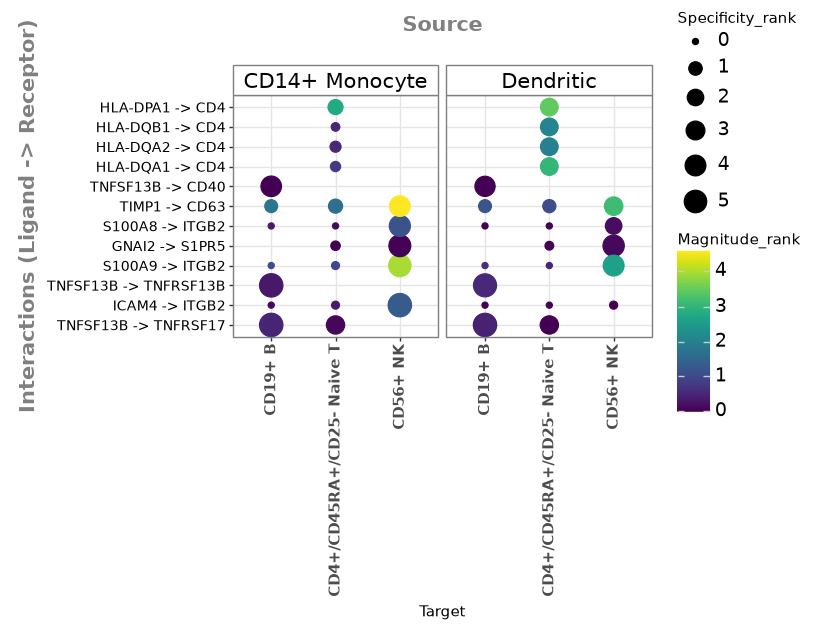

In [6]:
%matplotlib inline
p = li.pl.dotplot(adata=adata, colour="magnitude_rank", size="specificity_rank", inverse_colour=True, inverse_size=True,
              source_labels=["CD14+ Monocyte", "Dendritic"], target_labels=["CD4+/CD45RA+/CD25- Naive T", "CD19+ B", "CD56+ NK"],
              top_n=12, orderby="specificity_rank", orderby_ascending=True, figure_size=(8, 6))
p.draw()

## Options

- `mode="extra"` adds Null B as two further methods instead of replacing the tools' p (the benchmark recommends `"swap"`, the default).
- `null="null_a"` gives the six-method baseline with LIANA+'s own p.
- `strata="donor"` permutes labels within each donor (a column of `adata.obs`), for Null A and Null B alike.
- `aggregate_method="mean"` uses LIANA+'s mean aggregation instead of robust rank aggregation.